---
title: "04 · Evaluate the frozen decision"
---

Final evaluation answers a narrower question than model development: how did the frozen decision perform on the reserved samples? The final predictions were generated after the model freeze and are reused on compatible reruns.

In [1]:
from cancer_study.common import root, read_json
from IPython.display import SVG, display
import pandas as pd

project = root()
metrics_dir = project / "reports/metrics"
def figure(name):
    display(SVG(filename=str(project / "site/assets" / name)))

from cancer_study.evaluate import metrics
final = read_json(metrics_dir / "holdout.json")
predictions = pd.read_csv(metrics_dir / "holdout_predictions.csv", dtype={"sample_id": str}, float_precision="round_trip")
display(pd.Series(final))

n                                                                      114
positive_class                                               Malignant = 1
threshold                                                         0.547828
tn                                                                      72
fp                                                                       0
fn                                                                       3
tp                                                                      39
accuracy                                                          0.973684
sensitivity                                                       0.928571
specificity                                                            1.0
precision                                                              1.0
roc_auc                                                           0.996032
average_precision                                                 0.994274
brier_score              

## Count both kinds of error

Malignant is positive. Sensitivity measures the fraction of observed malignant samples detected; specificity measures the fraction of observed benign samples correctly cleared. Show the denominators as well as percentages.

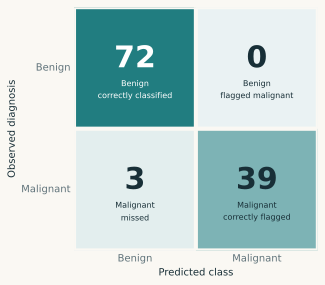

Malignant detected: 39/42
Benign cleared: 72/72


In [2]:
#| fig-alt: "Final holdout: 72 true negatives, zero false positives, three false negatives, and 39 true positives."
figure("holdout-confusion.svg")
print(f"Malignant detected: {final['tp']}/{final['tp'] + final['fn']}")
print(f"Benign cleared: {final['tn']}/{final['tn'] + final['fp']}")
recomputed = metrics(predictions.target, predictions.probability_malignant, final["threshold"])
for key in ["tp", "tn", "fp", "fn"]:
    assert recomputed[key] == final[key]

## Keep uncertainty visible

The sensitivity and specificity intervals use the Wilson score method at 95%. They condition on this model and this holdout sampling frame, and do not include all model-development uncertainty or external transportability.

In [3]:
for name in ["sensitivity", "specificity"]:
    lo, hi = final[f"{name}_wilson_95"]
    print(f"{name.capitalize()}: {final[name]:.1%} (95% Wilson: {lo:.1%}–{hi:.1%})")

Sensitivity: 92.9% (95% Wilson: 81.0%–97.5%)
Specificity: 100.0% (95% Wilson: 94.9%–100.0%)


## Inspect probability quality

ROC-AUC measures ranking. Brier score and the reliability plot describe probability quality. Five quantile bins are used, with limited observations per bin; the curve is uncertain and no recalibration is fitted here.

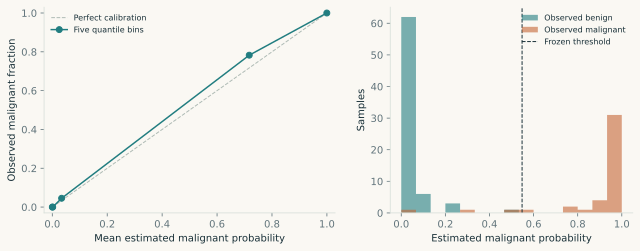

In [4]:
#| fig-alt: "Holdout reliability plot using five quantile bins and probability histograms by observed diagnosis."
figure("calibration.svg")

## Inspect every mistake

The table below is complete, not a selected set of examples. Observed labels are benchmark labels, not independently adjudicated ground truth. These observations were examined after final evaluation; they are not used to change the pipeline.

In [5]:
errors = predictions.loc[~predictions.correct].copy()
display(errors)
print(f"{len(errors)} errors out of {len(predictions)} holdout samples.")

,sample_id,diagnosis,target,probability_malignant,predicted,correct
12,859983,M,1,0.061429,0,False
37,874858,M,1,0.314532,0,False
40,879523,M,1,0.491610,0,False


3 errors out of 114 holdout samples.


## Conclusion and next evidence

The measurements contain a strong signal for the recorded class in this dataset. The performance claim remains bounded by a small historical cohort and an internal random holdout. The supplied table does not enable demographic or institutional subgroup checks, establish longitudinal patient independence, or support population screening claims.

Independent, compatible data would be required to evaluate external validity. Revising the model after examining these errors would require fresh evaluation evidence.